# Egyptian Ratscrew

Egyptian Ratscrew is a card game for two or more players. Deal a deck face down among the players. In turn, each player lays the top card of their stack face up on a shared pile. A royal **challenges** the next player, who must lay another royal within 1 card for a jack, 2 for a queen, 3 for a king or 4 for an ace. If they do, they challenge the next player in turn; if they don't, the player who laid the last royal takes the pile and puts it under their stack. Anyone may **slap** the pile when the top card matches the one below it (a pair) or the one below that (a sandwich), and the first to slap takes the pile, even a player who has run out of cards. The last player holding cards wins.

The code for dealing, slapping, challenges and whole games is in `game.py`, next to this notebook, so the tests can use it too. Suits never matter, so a card is just its rank.

In [1]:
import random
from statistics import mean, median

import matplotlib.pyplot as plt

from egyptian_ratscrew.game import (
    CHANCES,
    ROYALS,
    answer_chance,
    first_challenge,
    play,
    simulate_challenge,
)

## Questions

The first version of this notebook asked:

1. How likely is it that a challenge is answered, when nobody slaps?
2. How do the players' slapping speeds change the number of turns?
3. Does the distribution of game lengths look the same whatever the speeds?
4. How strongly does slapping faster go with winning?
5. If game lengths have a heavy tail, what statistics describe how long a game takes?
6. What is a useful "norm" on those distributions?

The sections below answer all six, and two more that came up on the way: whether laying the first card is an advantage, and how slapping by mistake changes the effect of speed. Reaction times are not modeled: each slap goes to player $i$ with a fixed chance, their **slap share**. Every pair or sandwich is slapped, and a game's length is the number of cards laid.

## Answering a challenge

At the start of a game a player lays a royal, and the other 51 cards are unseen and in random order: 15 royals and 36 other cards. The challenged player answers if a royal turns up within $k$ cards, which has chance $1 - \binom{36}{k} / \binom{51}{k}$.

Answering does not end the exchange, though: the answer is itself a challenge, which may be answered in turn. `first_challenge` follows the whole exchange, exactly, by recursion on the unseen cards, and gives the chance that the player who laid the first royal takes the pile. The tests check the recursion against every order of a few small decks.

In [2]:
print('royal  cards  answered  challenger keeps the pile')
for royal in ROYALS:
    k = CHANCES[royal]
    print(f'{royal:>5}  {k:5}  {float(answer_chance(k)):8.3f}  {float(first_challenge(royal)):26.3f}')

royal  cards  answered  challenger keeps the pile
    J      1     0.294                       0.811
    Q      2     0.506                       0.674
    K      3     0.657                       0.574
    A      4     0.764                       0.503


A jack is answered 29% of the time and an ace 76%. Over the whole exchange, the player who lays a jack keeps the pile 81% of the time, but the player who lays an ace keeps it only half the time: four chances to answer make the exchange a coin flip.

A simulation that deals out the 51 cards and plays each exchange agrees, within 1.4 standard errors for each royal:

In [3]:
rng = random.Random(1)
N = 20_000
for royal in ROYALS:
    p = float(first_challenge(royal))
    observed = sum(simulate_challenge(royal, rng) for _ in range(N)) / N
    print(f'{royal}: exact {p:.4f}, simulated {observed:.4f}, '
          f'{(observed - p) / (p * (1 - p) / N) ** 0.5:+.1f} standard errors')

J: exact 0.8115, simulated 0.8077, -1.4 standard errors


Q: exact 0.6735, simulated 0.6754, +0.5 standard errors


K: exact 0.5739, simulated 0.5759, +0.6 standard errors


A: exact 0.5030, simulated 0.5040, +0.3 standard errors


## The rules, checked against Beggar-my-neighbour

With no slapping, Egyptian Ratscrew is the old game Beggar-my-neighbour, whose longest known games are listed by [Richard Mann](https://richardpmann.com/beggar-my-neighbour-records.html) in a notation where `-` is any card that is not a royal. Two record deals end after exactly the published number of cards, 8,344 and 7,225. The first deal known never to end, found by Brayden Casella in 2024 ([Casella et al.](https://arxiv.org/abs/2403.13855)), is still going after 100,000 cards.

In [4]:
def hand(notation):
    return [card if card in CHANCES else 2 for card in notation]


deals = {
    'Nessler, 2022': ('---AJ--Q---------QAKQJJ-QK', '-----A----KJ-K--------A---'),
    'Wu, 2012': ('--A-Q--J--J---Q--AJ-K---K-', '-J-------Q------A--A--QKK-'),
    'Casella, 2024': ('---K---Q-KQAJ-----AAJ--J--', '----------Q----KQ-J-----KA'),
}
for name, (first, second) in deals.items():
    cards, winner = play([1, 1], random.Random(0), hands=[hand(first), hand(second)], slaps=False)
    print(f'{name}: {cards:,} cards, winner {winner}')

Nessler, 2022: 8,344 cards, winner 1
Wu, 2012: 7,225 cards, winner 0
Casella, 2024: 100,000 cards, winner None


## How long is a game?

Ten thousand games with equal slap shares, for two players and for four:

2 players: median 289 cards, mean 385, 90% under 802, 1% over 1,527, longest 2,800


4 players: median 1,051 cards, mean 1,423, 90% under 3,069, 1% over 5,837, longest 16,666


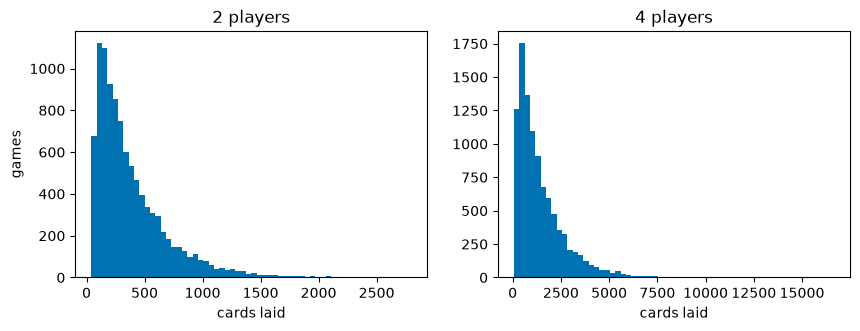

In [5]:
def games(shares, n, seed):
    rng = random.Random(seed)
    return [play(shares, rng) for _ in range(n)]


def quantile(sorted_values, q):
    return sorted_values[int(q * len(sorted_values))]


lengths = {}
for players, seed in ((2, 2), (4, 4)):
    results = games([1 / players] * players, 10_000, seed)
    assert all(winner is not None for _, winner in results)
    lengths[players] = sorted(cards for cards, _ in results)
    c = lengths[players]
    print(f'{players} players: median {median(c):,.0f} cards, mean {mean(c):,.0f}, '
          f'90% under {quantile(c, 0.9):,}, 1% over {quantile(c, 0.99):,}, longest {c[-1]:,}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, players in zip(axes, (2, 4), strict=True):
    ax.hist(lengths[players], bins=60, color='#0072B2')
    ax.set_title(f'{players} players')
    ax.set_xlabel('cards laid')
axes[0].set_ylabel('games')
plt.show()

Two players take a median of 289 cards and four players 1,051. Both distributions are skewed: the mean is a third larger than the median, and one game in a hundred lasts more than five times the median.

## Is the tail heavy?

A power law would make long games ever more likely to go on. They aren't. Of the two-player games still going after 300 cards, 27% end within the next 100 cards, and 27% or 28% do after 600, 900 and 1,200 cards. A constant ending rate means a geometric tail, which is a straight line when the share of games still going is plotted on a log scale:

after   300 cards: 4,772 games still going, 27% end within 100 more
after   600 cards: 1,862 games still going, 28% end within 100 more
after   900 cards:   735 games still going, 28% end within 100 more
after 1,200 cards:   281 games still going, 27% end within 100 more


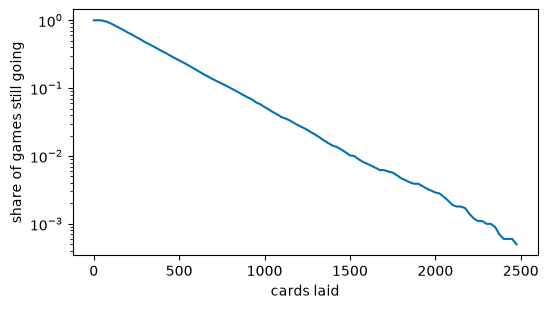

In [6]:
c = lengths[2]
for x in (300, 600, 900, 1200):
    left = sum(v > x for v in c)
    ended = left - sum(v > x + 100 for v in c)
    print(f'after {x:5,} cards: {left:5,} games still going, {ended / left:.0%} end within 100 more')

xs = range(0, 2500, 25)
plt.figure(figsize=(6, 3.2))
plt.semilogy(xs, [sum(v > x for v in c) / len(c) for x in xs], color='#0072B2')
plt.xlabel('cards laid')
plt.ylabel('share of games still going')
plt.show()

So a game is described by two numbers: its median length, and the rate at which long games end, about a quarter per 100 cards for two players. The mean adds little, and a power-law fit would be wrong.

## Faster slappers

Now two players whose slap shares differ: player 0 wins each slap with chance $s$. Four thousand games for each $s$, with a 95% Wilson interval on player 0's chance of winning:

share  wins   95% interval    median  90% under


  0.5  0.514  0.499-0.530     292        789


 0.55  0.641  0.627-0.656     284        763


  0.6  0.758  0.745-0.772     267        705


  0.7  0.899  0.890-0.908     217        546


  0.8  0.962  0.956-0.967     174        403


  0.9  0.988  0.984-0.991     145        312


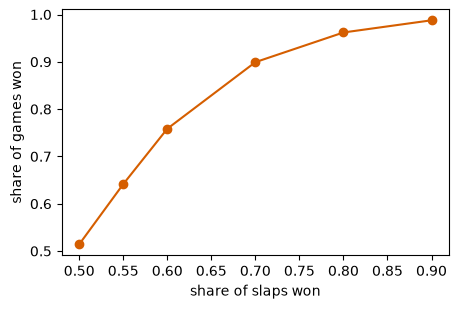

In [7]:
def wilson(wins, n, z=1.96):
    p = wins / n
    center = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * (p * (1 - p) / n + z * z / (4 * n * n)) ** 0.5 / (1 + z * z / n)
    return center - half, center + half


shares = (0.5, 0.55, 0.6, 0.7, 0.8, 0.9)
win_rates = []
print('share  wins   95% interval    median  90% under')
for s in shares:
    results = games([s, 1 - s], 4_000, int(s * 100))
    wins = sum(winner == 0 for _, winner in results)
    lo, hi = wilson(wins, len(results))
    c = sorted(cards for cards, _ in results)
    win_rates.append(wins / len(results))
    print(f'{s:5}  {wins / len(results):.3f}  {lo:.3f}-{hi:.3f}  {median(c):6,.0f}  {quantile(c, 0.9):9,}')

plt.figure(figsize=(5, 3.2))
plt.plot(shares, win_rates, 'o-', color='#D55E00')
plt.xlabel('share of slaps won')
plt.ylabel('share of games won')
plt.show()

Slapping decides the game. A player who wins 55% of the slaps wins 64% of the games; at 70% of the slaps, 90% of the games. Faster slapping also shortens games, from a median of about 290 cards to 145 when one player wins 90% of the slaps. The shape changes less: the 90th percentile falls from 2.7 times the median to 2.2.

## Who lays the first card?

In the 4,000 games at equal shares above, player 0, who lays the first card, won 51.4%, with an interval that reaches down to 49.9%. That is too few games to say whether laying first matters. `study.py` plays larger runs in seeded chunks of 5,000 games and records them in `runs.json`; they take under an hour on two cores, so this notebook reads the record, and replays the first chunk of a run to check it.

In [8]:
import json

from egyptian_ratscrew.study import RUNS, chunk_summary

runs = json.loads(RUNS.read_text())


def replays(run, chunk=0):
    """Play one recorded chunk again and compare its wins with the record."""
    wins = chunk_summary((run['shares'], run['seed'], chunk, run['options']))['wins']
    return wins == run['chunk_wins'][chunk]


def by_seat(run):
    n = run['games'] - run['unfinished']
    for seat, wins in enumerate(run['wins']):
        lo, hi = wilson(wins, n)
        print(f'  seat {seat}: {wins / n:.2%}  (95% interval {lo:.2%} to {hi:.2%})')


print('first chunk of the two-player run replays:', replays(runs['first_player_2']))
for name in ('first_player_2', 'first_player_4'):
    run = runs[name]
    print(f"{len(run['shares'])} players, {run['games']:,} games, seed {run['seed']}:")
    by_seat(run)

first chunk of the two-player run replays: True
2 players, 1,000,000 games, seed 1:
  seat 0: 49.77%  (95% interval 49.67% to 49.86%)
  seat 1: 50.23%  (95% interval 50.14% to 50.33%)
4 players, 200,000 games, seed 2:
  seat 0: 24.91%  (95% interval 24.72% to 25.10%)
  seat 1: 24.89%  (95% interval 24.70% to 25.08%)
  seat 2: 24.99%  (95% interval 24.80% to 25.18%)
  seat 3: 25.21%  (95% interval 25.02% to 25.41%)


Laying first is a small disadvantage for two players, not an advantage: player 0 wins 49.77% of a million games, and the interval, 49.67% to 49.86%, excludes 50%. The 51.4% above was chance. With four players the seats win 24.89% to 25.21% of 200,000 games; a chi-squared test of equal seats gives 5.3 on 3 degrees of freedom ($p \approx 0.15$), so no seat effect is detected. Why the first player loses slightly more often is not explained here.

## Beggar-my-neighbour from random deals

With slaps turned off, the same million-game run on random deals gives the statistics that others have published for Beggar-my-neighbour. A **trick** ends each time a pile is picked up, and a pile left on the table at the end counts as the last trick. For four record deals the counts of cards and tricks agree with BeggarMyPython, the checker linked from Mann's list (a test checks them). Mann's list itself gives one more trick for Manasse's deal (713) and one more card for Collins's (6,914).

1,000,000 deals, seed 3, 0 unfinished after 100,000 cards, first chunk replays: True
first player wins 49.87% (95% interval 49.77% to 49.97%)
cards: mean 254.6, median 192, 90% under 522, longest 3,174
tricks: mean 35.26, standard deviation 28.80, median 27, longest 433
  exactly 10 tricks: 2.701%
  exactly 11 tricks: 2.695%
  exactly 12 tricks: 2.683%
  6 to 28 tricks: 51.95%


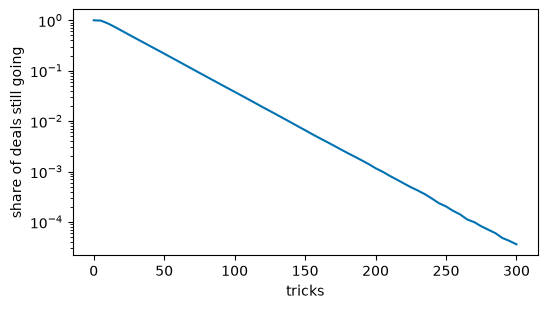

In [9]:
bmn = runs['beggar_my_neighbour']
n = bmn['games'] - bmn['unfinished']
lo, hi = wilson(bmn['wins'][0], n)
tricks = {int(t): count for t, count in bmn['tricks_counts'].items()}
print(f"{bmn['games']:,} deals, seed {bmn['seed']}, {bmn['unfinished']} unfinished after 100,000 cards, "
      f"first chunk replays: {replays(bmn)}")
print(f"first player wins {bmn['wins'][0] / n:.2%} (95% interval {lo:.2%} to {hi:.2%})")
cards, length = bmn['cards'], bmn['tricks']
print(f"cards: mean {cards['mean']:.1f}, median {cards['median']}, 90% under {cards['q90']}, longest {cards['max']:,}")
print(f"tricks: mean {length['mean']:.2f}, standard deviation {length['sd']:.2f}, median {length['median']}, longest {length['max']}")
for x in (10, 11, 12):
    print(f'  exactly {x} tricks: {tricks[x] / n:.3%}')
print(f'  6 to 28 tricks: {sum(v for x, v in tricks.items() if 6 <= x <= 28) / n:.2%}')

xs = range(0, 301, 5)
plt.figure(figsize=(6, 3.2))
plt.semilogy(xs, [sum(v for t, v in tricks.items() if t > x) / n for x in xs], color='#0072B2')
plt.xlabel('tricks')
plt.ylabel('share of deals still going')
plt.show()

These agree with what has been published, as far as it goes:

- [Truman Collins](http://tkcs-collins.com/truman/byn/byn.shtml) played 369.4 billion random deals and reports that the most common length is 11 tricks, with 2.70150% of deals, and that just over half end after 6 to 28 tricks. Here 11 tricks has 2.695%, within 0.4 standard errors of his figure (each share has a standard error of 0.016 points). The most common length here is 10 tricks, at 2.701%, which is also within noise of 11. Six to 28 tricks has 51.95%.
- A [GPU benchmark write-up](https://blog.speechmatics.com/pointless-gpu-optimization-exercise) gives an average of "about 250" cards; the mean here is 254.6.
- [Andorno et al. (2026)](https://arxiv.org/abs/2602.23406) simulate $10^7$ deals in each of several smaller settings, but not the standard 52-card one with four kinds of royal. In every setting they report, the player who leads first wins slightly less than half the time: 49.66% with 40 cards and four kinds of royal, 49.81% with 52 cards and three. Here, with 52 cards and four, the first player wins 49.87% (49.77% to 49.97%), the same direction and size. With slaps, the edge above is a little larger, 0.23 points.

The tail is geometric, as for the full game, and the share of deals still going falls on a straight line on the log scale. Of the deals still going after 20 tricks, half end within the next 20, and the same holds after 40, 60 and so on up to 160 tricks (between 49.6% and 50.6% each time). Andorno et al. also find an approximately exponential decay of match lengths in the settings they simulate.

## Misslaps

Real players slap by mistake. A common rule, given by [Bicycle](https://bicyclecards.com/how-to-play/egyptian-rat-screw) and [Wikipedia](https://en.wikipedia.org/wiki/Egyptian_Ratscrew), is that a player who slaps a pile that cannot be slapped puts a card (some groups say two) face down under the pile, where it goes to whoever takes the pile. Bicycle lets a player with no cards slap back in "as long as you don't slap at the wrong time"; here a player with no cards who misslaps is out of the game for good, which is how some rule sets settle it (Wikipedia gives three strikes as a variant).

`play_game` takes a **misslap rate** for each player: after every card that cannot be slapped, player $i$ misslaps with that chance and pays one card. Below, a fast but careless player, with slap share $s$ and misslap rate $m$, plays a slow but careful one, with share $1 - s$ who never misslaps. Each cell is 20,000 games with the seats alternated, so the first-player edge cancels.

first chunk of the last cell replays: True
fast player's chance of winning (95% intervals are within 0.7 points)
share    m = 0.0    m = 0.01   m = 0.02   m = 0.05   m = 0.1 
  0.5       0.502      0.466      0.428      0.346      0.235
 0.55       0.641      0.598      0.564      0.472      0.341
  0.6       0.755      0.721      0.696      0.601      0.459
 0.65       0.842      0.819      0.790      0.718      0.586
  0.7       0.902      0.883      0.870      0.804      0.696
 0.75       0.941      0.930      0.917      0.876      0.791
  0.8       0.965      0.956      0.950      0.921      0.860
cards paid per game at share 0.6: 0.0, 3.2, 6.4, 15.4, 28.1

rate   intercept  slope  share needed to win half
 0.0        0.02   5.50  0.498
0.01       -0.13   5.40  0.512
0.02       -0.28   5.38  0.526
0.05       -0.63   5.15  0.561
 0.1       -1.17   4.99  0.617


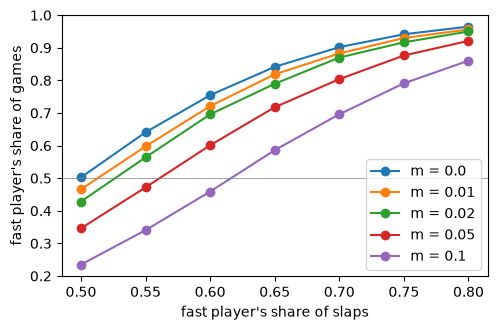

In [10]:
from math import log

from egyptian_ratscrew.study import FAST_SHARES, MISSLAP_RATES

misslaps = runs['misslaps']
print('first chunk of the last cell replays:', replays(misslaps[-1]))
cell = {(r['shares'][0], r['options']['misslaps'][0]): r for r in misslaps}
print('fast player\'s chance of winning (95% intervals are within 0.7 points)')
print('share ' + ''.join(f'   m = {m:<4}' for m in MISSLAP_RATES))
for s in FAST_SHARES:
    print(f'{s:5} ' + ''.join(f"  {cell[s, m]['wins'][0] / cell[s, m]['games']:9.3f}" for m in MISSLAP_RATES))
print('cards paid per game at share 0.6:',
      ', '.join(f"{cell[0.6, m]['paid'] / cell[0.6, m]['games']:.1f}" for m in MISSLAP_RATES))


def logit_line(points):
    """Least-squares line through (2s - 1, logit of the win chance)."""
    xs = [2 * s - 1 for s, _ in points]
    ys = [log(w / (1 - w)) for _, w in points]
    mx, my = sum(xs) / len(xs), sum(ys) / len(ys)
    slope = sum((x - mx) * (y - my) for x, y in zip(xs, ys, strict=True)) / sum((x - mx) ** 2 for x in xs)
    return my - slope * mx, slope


print('\nrate   intercept  slope  share needed to win half')
plt.figure(figsize=(5.5, 3.4))
for m in MISSLAP_RATES:
    points = [(s, cell[s, m]['wins'][0] / cell[s, m]['games']) for s in FAST_SHARES]
    a, b = logit_line(points)
    print(f'{m:4}  {a:10.2f}  {b:5.2f}  {0.5 - a / (2 * b):.3f}')
    plt.plot(*zip(*points, strict=True), 'o-', label=f'm = {m}')
plt.axhline(0.5, color='gray', lw=0.5)
plt.xlabel("fast player's share of slaps")
plt.ylabel("fast player's share of games")
plt.legend()
plt.show()

Misslaps shift the curve to the right and barely change its shape. On the logit scale each curve is close to a straight line in $2s - 1$; the slope falls only from 5.5 to 5.0 as the misslap rate rises to 10%, while the intercept falls by about 0.12 to 0.14 for each point of misslap rate. So each point of misslap rate costs about as much as 1.2 to 1.4 points of slap share: a player who misslaps after 1 card in 100 needs 51.2% of the slaps to break even, at 5% they need 56.1%, and at 10%, 61.7%. These break-even shares come from the fitted lines.

A misslap costs less than a card. At a 5% rate the careless player pays about 15 cards a game, but each goes under the pile, and the fast player takes most piles, so many of those cards come back.

## A norm on slap shares

Question 6 asked for a single number that says how unequal the slap shares are and predicts who wins. With two players one share says everything, and the curve above is close to $\operatorname{logit} w = c\,(s_0 - s_1)$, a straight line on the logit scale. Fitting $c$ by maximum likelihood to 20,000 games at each of nine shares, with the seats alternated:

In [11]:
from statistics import fmean

from egyptian_ratscrew.study import (
    entropy,
    fit,
    power,
    proportional,
    rmse,
    softmax,
    spearman,
    two_player_against_field,
)

two = [(r['shares'], r['wins']) for r in runs['two_player_curve']]
c_two = fit(softmax, two, 0.1, 30)
k_two = fit(power, two, 0.1, 10)
print(f'c = {c_two:.2f}, and for comparison the best power law has k = {k_two:.2f}')
print('share  observed  logistic  power')
for shares, wins in two:
    print(f'{shares[0]:5}  {wins[0] / sum(wins):8.4f}  {softmax(c_two)(shares)[0]:8.4f}  {power(k_two)(shares)[0]:5.4f}')

c = 5.50, and for comparison the best power law has k = 2.46
share  observed  logistic  power
  0.5    0.5055    0.5000  0.5000
 0.55    0.6351    0.6342  0.6210
  0.6    0.7486    0.7503  0.7306
 0.65    0.8422    0.8390  0.8210
  0.7    0.9015    0.9003  0.8894
 0.75    0.9372    0.9400  0.9372
  0.8    0.9648    0.9645  0.9680
 0.85    0.9799    0.9792  0.9862
  0.9    0.9872    0.9879  0.9955


The logistic curve is within 0.006 of every observed rate, at most 1.6 standard errors; the power law $w_0 = s_0^k / (s_0^k + s_1^k)$, the Bradley-Terry form with strength $s^k$, misses by up to 0.018.

With more players, each player needs a **strength**, and wins with chance proportional to it. The candidates, each fixed by the two-player games alone:

- **proportional**: win chance equal to slap share;
- **power**: strength $s_i^k$ with $k = 2.46$ from the two-player fit;
- **logistic**: strength $e^{c s_i}$ with $c = 5.50$; for two players this is the curve above;
- **scaled logistic**: strength $e^{c n s_i / 2}$. For two players it is the same curve. For $n$ players it says that two players $i$ and $j$ face the same odds as in a two-player game with share difference $n (s_i - s_j)/2$, so a share counts relative to the even share $1/n$;
- **against the field**: the two-player curve at the effective share $s_i / (s_i + \bar s_{-i})$, where $\bar s_{-i}$ is the mean share of the others, normalized to sum to 1.

Each is tested on 60 random share vectors for three players and 60 for four, drawn from a symmetric Dirichlet distribution with parameter 2, with 4,000 games per vector and the seats rotated. The table gives the root mean square error of every player's predicted win chance. Sampling alone would give an error of about 0.005. The last two rows refit the parameter to the many-player games, which shows how well each form can do at best.

In [12]:
models = {
    'proportional': lambda n: proportional,
    'power': lambda n: power(k_two),
    'logistic': lambda n: softmax(c_two),
    'scaled logistic': lambda n: softmax(c_two * n / 2),
    'against the field': lambda n: two_player_against_field(c_two),
}
data = {n: [(r['shares'], r['wins']) for r in runs[f'vectors_{n}']] for n in (3, 4)}
win_share = {n: [w / sum(ws) for _, ws in data[n] for w in ws] for n in (3, 4)}
k_refit = {n: fit(power, data[n], 0.1, 10) for n in (3, 4)}
c_refit = {n: fit(softmax, data[n], 0.1, 60) for n in (3, 4)}
for n in (3, 4):
    floor = (fmean(p * (1 - p) for p in win_share[n]) / 4000) ** 0.5
    print(f'{n} players: sampling error alone {floor:.4f}; refitted k = {k_refit[n]:.2f}, c = {c_refit[n]:.2f} (scaled: {c_two * n / 2:.2f})')
print('\nmodel                      3 players  4 players')


def error(model, n):
    return rmse([p for shares, _ in data[n] for p in model(shares)], win_share[n])


for name, make in models.items():
    print(f'{name:25}  {error(make(3), 3):9.4f}  {error(make(4), 4):9.4f}')
print(f"{'power, refitted':25}  {error(power(k_refit[3]), 3):9.4f}  {error(power(k_refit[4]), 4):9.4f}")
print(f"{'logistic, refitted':25}  {error(softmax(c_refit[3]), 3):9.4f}  {error(softmax(c_refit[4]), 4):9.4f}")

3 players: sampling error alone 0.0052; refitted k = 3.02, c = 8.53 (scaled: 8.25)
4 players: sampling error alone 0.0046; refitted k = 3.20, c = 10.62 (scaled: 11.00)

model                      3 players  4 players
proportional                  0.1713     0.1799
power                         0.0377     0.0470
logistic                      0.0706     0.1086
scaled logistic               0.0167     0.0216
against the field             0.1016     0.1508
power, refitted               0.0101     0.0090
logistic, refitted            0.0165     0.0211


The scaled logistic is the best prediction made from two-player games alone, with errors of 0.017 and 0.022, about four times sampling error. Its scaling is right: fitting $c$ to the many-player games directly gives 8.53 and 10.62, close to the predicted $5.50 \cdot n/2$ = 8.25 and 11.00, and no better error. Its shape is not quite right, though. A power law with $k$ refitted for each number of players ($k$ = 3.02 and 3.20) has the smallest errors, 0.010 and 0.009, while the same power law fitted to two players ($k$ = 2.46) is poor for two players and for more. Neither form is exact, and the refitted power law needs a parameter that grows with the number of players.

The proportional and against-the-field models are far off: faster slapping is worth much more than its share, and an average of the others hides how strong the strongest rival is.

For one number that summarizes a whole share vector, the natural target is the favorite's chance of winning. Rank correlations of each summary with the favorite's observed win chance:

summary                       3 players  4 players
largest share                     0.960      0.969
sum of squared shares             0.783      0.895
minus entropy                     0.715      0.846
scaled logistic, favorite         0.997      0.993


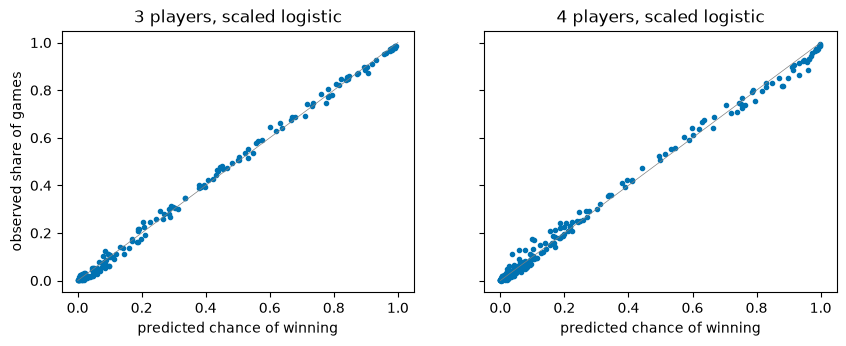

In [13]:
summaries = {
    'largest share': lambda shares, n: max(shares),
    'sum of squared shares': lambda shares, n: sum(s * s for s in shares),
    'minus entropy': lambda shares, n: -entropy(shares),
    'scaled logistic, favorite': lambda shares, n: max(softmax(c_two * n / 2)(shares)),
}
print('summary                       3 players  4 players')
favorite = {n: [ws[shares.index(max(shares))] / sum(ws) for shares, ws in data[n]] for n in (3, 4)}
for name, f in summaries.items():
    rho = [spearman([f(shares, n) for shares, _ in data[n]], favorite[n]) for n in (3, 4)]
    print(f'{name:28}  {rho[0]:9.3f}  {rho[1]:9.3f}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, n in zip(axes, (3, 4), strict=True):
    model = softmax(c_two * n / 2)
    ax.plot([p for shares, _ in data[n] for p in model(shares)], win_share[n], '.', color='#0072B2')
    ax.plot([0, 1], [0, 1], color='gray', lw=0.5)
    ax.set_title(f'{n} players, scaled logistic')
    ax.set_xlabel('predicted chance of winning')
axes[0].set_ylabel('observed share of games')
plt.show()

The symmetric summaries that a "norm" suggests, entropy and the sum of squares, rank the vectors poorly (0.72 to 0.90), because they weigh the spread among the slow players as much as the lead of the fast one. The largest share does better (0.96 and 0.97). The favorite's chance under the scaled logistic does best (0.997 and 0.993), and the same model gives every other player's chance too.

So the most useful single number is not a norm of the share vector but a strength per player, $e^{2.75\, n s_i}$: each even share's worth of slaps multiplies a player's strength by $e^{2.75} \approx 16$. It comes from the two-player curve alone, predicts many-player win chances to within about 0.02, and is an empirical fit rather than a derived law.

## Questions left open

- **Why laying first loses.** The first player's disadvantage, 0.23 points with slaps and 0.13 without, is measured here but not explained.
- **A better strength.** The scaled logistic gets the scaling with the number of players right and the power law gets the shape right; a form with both might reach sampling error.
- **Reaction times.** A share per slap ignores that a sandwich is harder to spot than a pair, and that a careless player is careless because they are fast.
- **More players.** Four players take three to four times as long as two; how does the length grow with the number of players?